In [1]:
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.tasks import select_task
from grokkingexperiments.train import train_model


import torch
import tomllib
from pydantic import BaseModel, PositiveInt, PositiveFloat
from typing import Literal


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train")

Using cuda to train


Classes To Validate Config

In [ ]:
class TaskConfig(BaseModel):
    type : Literal["group", "operation"]
    name : Literal["Zn", "bitwise_and"]
    n : PositiveInt
    split : PositiveFloat


class ModelConfig(BaseModel):
    actv_func : Literal["relu", "tanh", "sigmoid"]
    embed_dim : PositiveInt
    hidden_dim : PositiveInt

class TrainingConfig(BaseModel):
    epochs : PositiveInt

class Config(BaseModel):
    model: ModelConfig
    train: TrainingConfig
    task : TaskConfig

def load_config():
    with open("config.toml", "rb") as f:
        config = tomllib.load(f)
    config = Config.model_validate(config)
    return config


def print_config(cfg):
    for section, fields in cfg.model_dump().items():
        print(f"{section}")
        for key, value in fields.items():
            print(f"| {key : <15} {value}")
        print("")

model
| actv_func       relu
| embed_dim       128
| hidden_dim      256

train
| epochs          20000

task
| type            group
| name            Zn
| n               64
| split           0.4

Epoch  0      | Loss 4.186  | Test loss 4.200  | Train accuracy 0.013  | Test accuracy 0.010 
Epoch  100    | Loss 0.431  | Test loss 8.862  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  200    | Loss 0.067  | Test loss 10.176 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  300    | Loss 0.045  | Test loss 9.940  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.037  | Test loss 9.664  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.031  | Test loss 9.408  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.027  | Test loss 9.170  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.024  | Test loss 8.932  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.021  | Test loss 8.700  | 

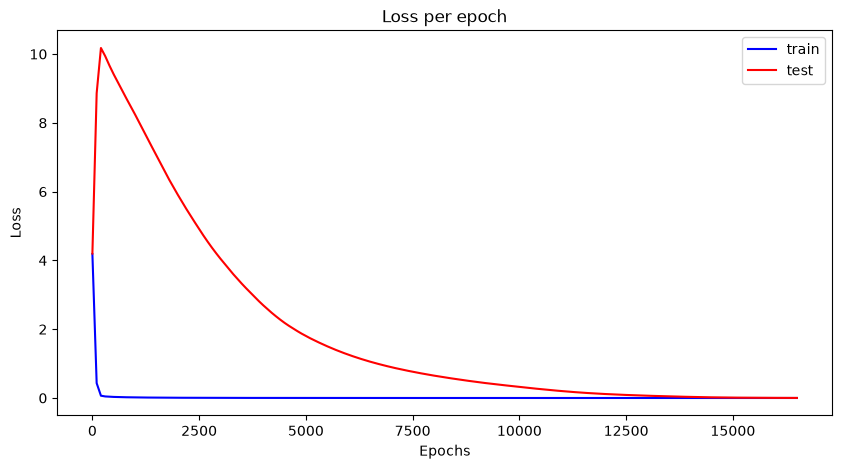

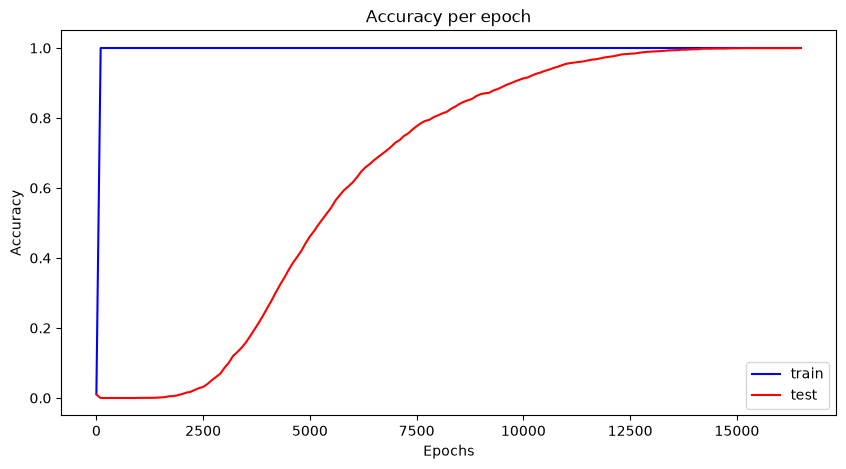

In [ ]:
# Load Config
config = load_config()
print_config(config)

# Get the training task and data
task = select_task(config)
x_train, y_train, x_test, y_test =  task.generate_train_test_data(0.4)

# Move datasets to the gpu if available
x_train = x_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)


# Generate the model and move to gpu
model = GrokkingModel(config)
model = model.to(device)


train_model(config.train.epochs, model,  x_train,y_train, x_test,y_test)

model.plot_metrics()